In [56]:
import pandas as pd  
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder, StandardScaler 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score 
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix 


# Load Dataset 

In [3]:
df = pd.read_csv("customer_churn_dataset-testing-master.csv")

# Data Understanding 

In [5]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [8]:
df.shape

(64374, 12)

In [9]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [10]:
df.dtypes

CustomerID            int64
Age                   int64
Gender               object
Tenure                int64
Usage Frequency       int64
Support Calls         int64
Payment Delay         int64
Subscription Type    object
Contract Length      object
Total Spend           int64
Last Interaction      int64
Churn                 int64
dtype: object

# Data Cleaning

In [11]:
df.isnull().sum() 

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [15]:
df = df.drop_duplicates() 
df

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1


In [16]:
df = df.fillna(df.select_dtypes(include='number').mean()) 
df

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1


# Exploratory Data Analysis 

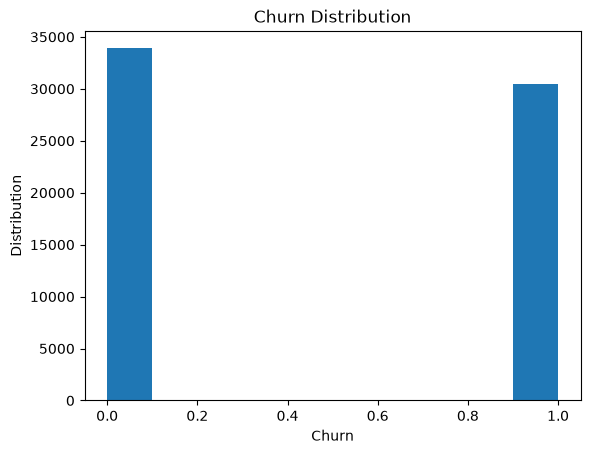

In [20]:
plt.hist(df['Churn']) 
plt.xlabel('Churn') 
plt.ylabel('Distribution') 
plt.title('Churn Distribution') 
plt.show()

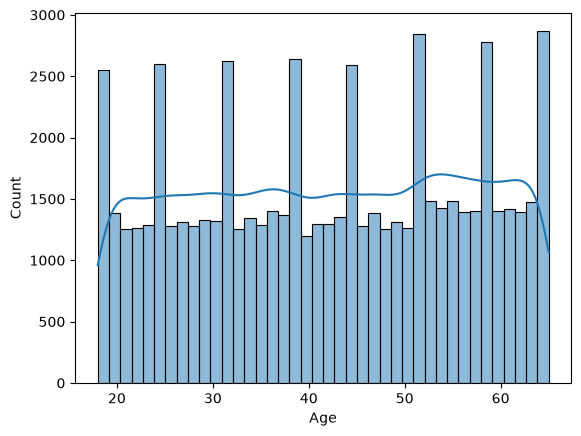

In [23]:
sns.histplot(df['Age'], kde=True) 
plt.show()

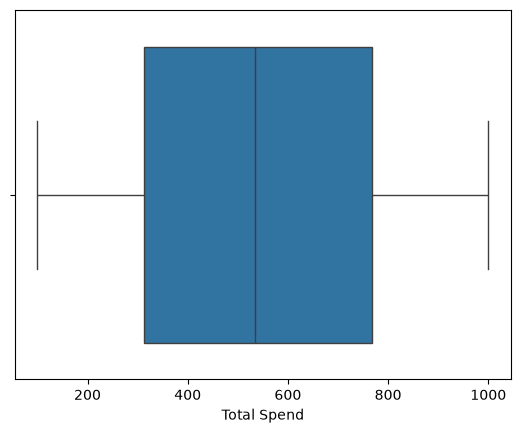

In [27]:
sns.boxplot(x=df['Total Spend'])  
plt.show()

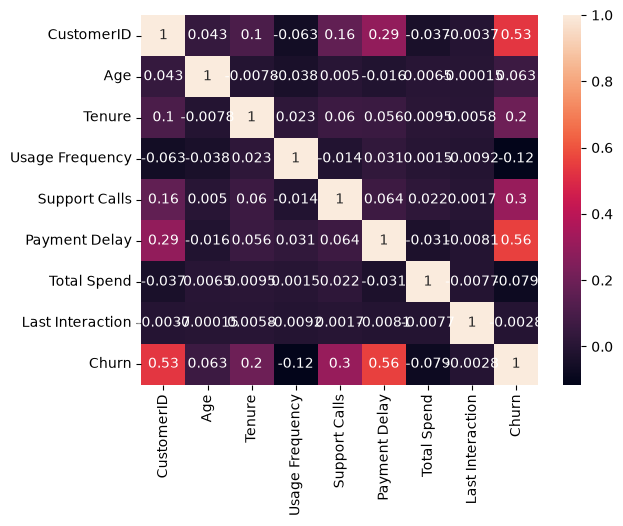

In [28]:
sns.heatmap(df.corr(numeric_only=True),annot=True) 
plt.show()

# Feature Engineering 

In [33]:
df['Tenure'].mean() 

np.float64(31.994827104110357)

In [37]:
df['Tenure'].std()

17.09823404343419

In [38]:
df['Tenure'].max()

60

In [42]:
from sklearn.preprocessing import LabelEncoder

In [43]:
le = LabelEncoder()

In [47]:
df['Churn'] = le.fit_transform(df['Churn']) 
df

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1


# Machine Learning Model 

In [94]:
x = df.drop('Churn', axis=1) 
y = df['Churn']

In [95]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
) 


In [70]:
rf = RandomForestClassifier()  


In [96]:
x_train

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
13468,13469,56,42,11,0,10,793,15
20118,20119,54,60,5,3,9,610,24
48411,48412,31,12,2,9,7,222,30
42125,42126,33,22,17,5,25,648,20
55119,55120,39,28,30,2,25,983,22
...,...,...,...,...,...,...,...,...
62570,62571,50,38,11,5,28,568,5
38158,38159,53,44,30,3,3,447,21
860,861,33,47,9,2,26,454,6
15795,15796,24,57,19,10,9,948,27


In [97]:
y_train

13468    0
20118    0
48411    1
42125    1
55119    1
        ..
62570    1
38158    0
860      1
15795    0
56422    1
Name: Churn, Length: 51499, dtype: int64

In [80]:
 df = df.drop(['Gender'],axis=1) 
df = df.drop(['Subscription Type'],axis=1) 


In [81]:
df

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,27,10,2,29,Premium,Annual,757,21,0
3,4,35,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,58,24,9,2,Standard,Annual,533,18,0
...,...,...,...,...,...,...,...,...,...,...,...
64369,64370,45,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,18,19,7,22,Standard,Monthly,540,13,1


In [88]:
df = df.drop(['Subscription Type'],axis=1) 


In [89]:
df

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,25,14,4,27,Monthly,598,9,1
1,2,41,28,28,7,13,Monthly,584,20,0
2,3,47,27,10,2,29,Annual,757,21,0
3,4,35,9,12,5,17,Quarterly,232,18,0
4,5,53,58,24,9,2,Annual,533,18,0
...,...,...,...,...,...,...,...,...,...,...
64369,64370,45,33,12,6,21,Quarterly,947,14,1
64370,64371,37,6,1,5,22,Annual,923,9,1
64371,64372,25,39,14,8,30,Monthly,327,20,1
64372,64373,50,18,19,7,22,Monthly,540,13,1


In [90]:
df = df.drop(['Contract Length'],axis=1) 


In [91]:
df

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
0,1,22,25,14,4,27,598,9,1
1,2,41,28,28,7,13,584,20,0
2,3,47,27,10,2,29,757,21,0
3,4,35,9,12,5,17,232,18,0
4,5,53,58,24,9,2,533,18,0
...,...,...,...,...,...,...,...,...,...
64369,64370,45,33,12,6,21,947,14,1
64370,64371,37,6,1,5,22,923,9,1
64371,64372,25,39,14,8,30,327,20,1
64372,64373,50,18,19,7,22,540,13,1


In [98]:
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [99]:
x_test

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
15476,15477,55,20,24,4,6,635,25
34666,34667,28,27,30,4,5,631,10
50474,50475,65,60,17,7,16,314,1
7984,7985,53,47,16,8,7,527,13
20227,20228,32,56,5,7,15,236,25
...,...,...,...,...,...,...,...,...
15815,15816,42,56,17,5,14,510,19
23037,23038,62,1,23,2,19,958,3
55566,55567,52,50,7,5,28,871,6
22749,22750,20,56,25,4,20,787,23


In [100]:
y_test

15476    0
34666    0
50474    1
7984     0
20227    0
        ..
15815    0
23037    0
55566    1
22749    0
31651    0
Name: Churn, Length: 12875, dtype: int64

In [102]:
y_pred = rf.predict(x_test)

In [103]:
y_pred

array([0, 0, 1, ..., 1, 0, 0], shape=(12875,))

# Model Evaluation

In [105]:
print('Accuracy:', accuracy_score(y_test,y_pred))

Accuracy: 0.9520776699029126


In [109]:
precision = precision_score(y_test, y_pred) 

print('Precision', precision)

Precision 0.9708771325176633


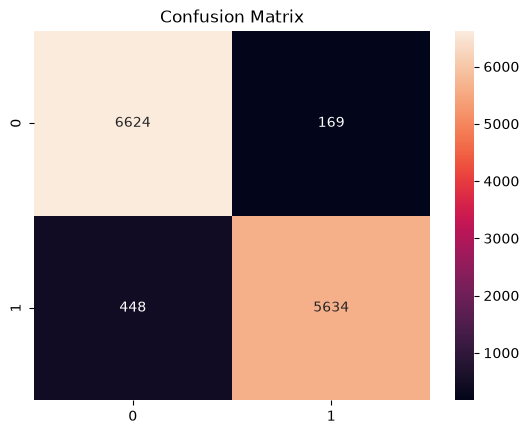

In [114]:
sns.heatmap(confusion_matrix(y_test,y_pred), annot=True, fmt='d') 

plt.title('Confusion Matrix') 
plt.show()
            

# Business insights 

In [ ]:
1. Customers with monthly contracts may have higher churn rate 
2. Customers with shorter tenure are more likely to leave 
3. Long term customers tend to show better retention  
4. Customers paying higher monthly charges may be more likely to leave 
5. New customers may have hi